# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arshiyanaaz411/flyrank-ml-internship/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

In [2]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_absolute_error
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# ---- CREATE DUMMY DATA FOR RUNNING THE NOTEBOOK ----
# This ensures the playbook runs without a 'file not found' or missing column error.
import numpy as np
import pandas as pd
np.random.seed(42)
n_samples = 200
dummy_df = pd.DataFrame({
    'client_id': np.random.choice([f'client_{i}' for i in range(1, 11)], size=n_samples),
    'item_id': [f'item_{i}' for i in range(n_samples)],
    'ctr': np.clip(np.random.normal(0.05, 0.02, size=n_samples), 0.005, 0.15),
    'impressions': np.random.randint(10, 5000, size=n_samples),
    'age_days': np.random.randint(1, 365, size=n_samples),
    'feature_engagement': np.random.uniform(0.1, 1.0, size=n_samples),
    'feature_shares': np.random.randint(0, 100, size=n_samples),
    'archetype_cluster': np.random.choice(['A0', 'A1', 'A2', 'A3'], size=n_samples)
})
dummy_df.to_csv('your_data.csv', index=False)

# ---- EDIT THESE (same names as Week 5/6) ----
DATA_PATH = "your_data.csv"     # anonymized sample
TARGET = "ctr"
GROUP = "client_id"
ID_COL = "item_id"              # an anonymized item id if you have one, else None
IMPR_COL = "impressions"        # impressions column, or None
AGE_COL = "age_days"            # days since publish, or None
ARCHETYPE_COL = "archetype_cluster" # existing archetype/cluster column, or None
DROP_FEATURES = []              # leakage suspects you dropped in Week 6
# ---------------------------------------------

os.makedirs("work/outputs", exist_ok=True)
os.makedirs("work/figures", exist_ok=True)

df = pd.read_csv(DATA_PATH).dropna(subset=[TARGET, GROUP]).reset_index(drop=True)
skip = {TARGET, GROUP, ID_COL, ARCHETYPE_COL} | set(DROP_FEATURES)
FEATURES = [c for c in df.select_dtypes("number").columns if c not in skip]
X, y, g = df[FEATURES], df[TARGET], df[GROUP]

# Honest out-of-fold predictions: every row is predicted by a model that never saw its client
hgb = lambda: HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=42)
oof = np.full(len(df), np.nan)
oof_base = np.full(len(df), np.nan)
for tr, va in GroupKFold(5).split(X, y, groups=g):
    oof[va] = hgb().fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[va])
    oof_base[va] = DummyRegressor(strategy="median").fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[va])

df["pred_ctr"] = oof
df["gap"] = df["pred_ctr"] - df[TARGET]           # positive = performing below model expectation
MAE_MODEL = mean_absolute_error(y, oof)
MAE_BASE = mean_absolute_error(y, oof_base)
print(f"Grouped OOF MAE: model {MAE_MODEL:.4f} | baseline {MAE_BASE:.4f}")

Grouped OOF MAE: model 0.0194 | baseline 0.0176


**Idea:** the model gives an expected CTR for each item. If an item sits well below its expected CTR, it is a candidate for human review. This is decision-support, not an automatic verdict.

**Noise floor:** a gap smaller than the model's own MAE (measured under grouped CV) is treated as noise and gets no action.

**Reason codes (rule-based, readable by a human):**
- `R1_BELOW_EXPECTED`: actual CTR is below the model's expectation by more than the noise floor.
- `R2_AGED`: the item is older than the refresh threshold (see the decay insight below).
- `R3_LOW_VOLUME`: too few impressions, so CTR is unstable. Always goes to a human, never to an action.
- `R4_WITHIN_NOISE`: gap is inside the noise floor. Monitor only.

**Actions:** `REFRESH_CONTENT` (R1 + R2), `REVIEW_TITLE_SNIPPET` (R1 only), `HOLD_LOW_VOLUME` (R3), `MONITOR` (R4 or no flag).

**Priority:** items are ranked by estimated opportunity = impressions x positive gap (extra clicks if the item reached its expected CTR). This is a directional estimate, not a forecast.## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

In [3]:
# ---- thresholds: assumptions, edit and justify in the markdown above ----
MIN_IMPR = 100          # below this, CTR is unstable
AGE_REFRESH = 180       # days; set after looking at the decay plot below
NOISE_FLOOR = MAE_MODEL
# ------------------------------------------------------------------------

impr = df[IMPR_COL] if IMPR_COL else pd.Series(1.0, index=df.index)
age = df[AGE_COL] if AGE_COL else pd.Series(np.nan, index=df.index)

r1 = df["gap"] > NOISE_FLOOR
r2 = (age >= AGE_REFRESH) if AGE_COL else pd.Series(False, index=df.index)
r3 = (impr < MIN_IMPR) if IMPR_COL else pd.Series(False, index=df.index)
r4 = df["gap"].abs() <= NOISE_FLOOR

codes = pd.DataFrame({"R1_BELOW_EXPECTED": r1, "R2_AGED": r2,
                      "R3_LOW_VOLUME": r3, "R4_WITHIN_NOISE": r4})
df["reason_codes"] = codes.apply(lambda r: "|".join([c for c in codes.columns if r[c]]) or "NONE", axis=1)

def pick_action(i):
    if r3[i]: return "HOLD_LOW_VOLUME"
    if r1[i] and r2[i]: return "REFRESH_CONTENT"
    if r1[i]: return "REVIEW_TITLE_SNIPPET"
    return "MONITOR"

df["action"] = [pick_action(i) for i in df.index]
df["opportunity"] = impr * df["gap"].clip(lower=0)
print(df["action"].value_counts())

action
MONITOR                 159
REFRESH_CONTENT          20
REVIEW_TITLE_SNIPPET     20
HOLD_LOW_VOLUME           1
Name: count, dtype: int64


In [4]:
if ARCHETYPE_COL:
    df["archetype"] = df[ARCHETYPE_COL].astype(str)
else:
    ARCH_FEATURES = FEATURES[:5]       # EDIT: pick features that describe content behavior
    Z = StandardScaler().fit_transform(df[ARCH_FEATURES].fillna(df[ARCH_FEATURES].median()))
    df["archetype"] = "A" + pd.Series(KMeans(4, n_init=10, random_state=42).fit_predict(Z), index=df.index).astype(str)

profile_cols = [c for c in ([AGE_COL, IMPR_COL] if AGE_COL or IMPR_COL else []) if c] + [TARGET, "pred_ctr", "gap"]
display(df.groupby("archetype")[profile_cols].median().round(4).assign(n=df["archetype"].value_counts()))

,age_days,impressions,ctr,pred_ctr,gap,n
archetype,,,,,,
A0,183.0,3082.0,0.0516,0.0514,-0.0014,61
A1,140.0,2789.0,0.0431,0.0504,-0.0029,49
A2,151.0,3029.0,0.0545,0.0474,-0.0061,43
A3,168.0,2766.0,0.0517,0.0503,-0.0044,47


**Intended use:** a ranked review queue that helps an editor decide which items to look at first. It is decision-support for planning refresh work.

**What the evidence supports (measured):** under grouped CV, MAE was ___ vs baseline ___ (Week 6). The model finds items that are lower than expected given their features.

**Limits:**
- Trained on one sample and one time period. Performance on other periods or other kinds of clients is not shown.
- The gap is "below model expectation", not "bad content". The model cannot see content quality, intent changes, or seasonality unless they are in the features.
- Opportunity numbers are directional estimates. They assume the item could reach its expected CTR, which is not guaranteed.
- Feature importance shows what the model uses, not what causes CTR.
- Non-production: this notebook produces a plan and a queue, not a deployed system.## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*

In [5]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


**Human review rules**
- A person reads every item in the top queue before any change is made.
- Every `HOLD_LOW_VOLUME` item is reviewed by a person or left alone, never auto-actioned.
- The reviewer sees the reason codes and the gap, and may override the action with a written reason.
- Spot-check a sample of `MONITOR` items to catch misses.

**Do NOT automate (no-go list)**
- Publishing, rewriting, or deleting content from the queue without human approval.
- Pruning or removing pages based on CTR gap alone.
- Client-facing promises such as "this refresh will lift CTR by X".
- Items with very low volume, brand-new items with no history, or items in a client or segment not represented in the sample.
- Any use of the queue to rank or judge people or teams.
- Reading feature importance as a cause.
- Using the queue after a drift or retrain trigger (next section) fires, until it is re-validated.## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

In [6]:
# Assumptions, not measurements. Replace with realistic numbers and say so.
EFFORT_HRS = {"REFRESH_CONTENT": 3.0, "REVIEW_TITLE_SNIPPET": 0.5,
              "HOLD_LOW_VOLUME": 0.25, "MONITOR": 0.0}

cv = (df.groupby("action")
        .agg(items=("action", "size"), est_extra_clicks=("opportunity", "sum"))
        .assign(effort_hrs=lambda t: t.index.map(EFFORT_HRS) * t["items"]))
cv["clicks_per_hour"] = (cv["est_extra_clicks"] / cv["effort_hrs"]).replace([np.inf], np.nan)
display(cv.round(2))

,items,est_extra_clicks,effort_hrs,clicks_per_hour
action,,,,
HOLD_LOW_VOLUME,1,0.40,0.25,1.62
MONITOR,159,1188.12,0.00,NaN
REFRESH_CONTENT,20,1647.84,60.00,27.46
REVIEW_TITLE_SNIPPET,20,2639.93,10.00,263.99


**Reading the table (directional):** cheap title/snippet reviews may give more estimated clicks per hour than full refreshes, or not. Check ___ in the table.
**Assumptions:** effort hours are my placeholders, and est_extra_clicks assumes items reach expected CTR. Treat the ratio as a way to order work, not as an ROI claim.
**Cost of a wrong call:** a wasted refresh costs editor hours; a missed item costs lost clicks. This is why the queue stays human-reviewed.

**Light monitoring (when a new batch of data arrives):**
- **Input drift:** PSI per top feature vs the training sample. Above 0.25 means "look closely".
- **Error check:** MAE on new data with known outcomes vs the grouped-CV MAE of ___. If it is more than 20% worse, pause the queue.
- **Baseline check:** if the model stops beating the baseline on new data, stop using it.
- **Queue sanity:** if the share of items flagged moves sharply (for example 2x), investigate before using the queue.

**Retrain triggers:** any trigger above fires, a new client segment is added, a major change in how CTR is measured, or on a regular schedule of ___ (for example every quarter) as a safety net. After retraining, re-run the grouped validation before use.## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

In [7]:
def psi(a, b, bins=10):
    a, b = pd.Series(a).dropna(), pd.Series(b).dropna()
    edges = np.unique(np.quantile(a, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3: return np.nan
    pa = np.histogram(a, bins=edges)[0] / len(a)
    pb = np.histogram(b, bins=edges)[0] / len(b)
    pa, pb = np.clip(pa, 1e-4, None), np.clip(pb, 1e-4, None)
    return float(np.sum((pb - pa) * np.log(pb / pa)))

# Sanity check of the function: split by client into two halves (PSI should be small)
ids = g.unique(); rng = np.random.RandomState(1); rng.shuffle(ids)
half = set(ids[: len(ids) // 2])
mask = g.isin(half)
top = df[FEATURES].var().sort_values(ascending=False).index[:5]
print({f: round(psi(df.loc[mask, f], df.loc[~mask, f]), 3) for f in top})

TRIGGERS = {"psi_look_closely": 0.25, "mae_worse_than_cv_pct": 20,
            "must_beat_baseline": True, "flag_share_change_factor": 2.0,
            "scheduled_retrain": "quarterly (assumption)"}

{'impressions': 0.219, 'age_days': 0.064, 'feature_shares': 0.14, 'feature_engagement': 0.123}


## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*

In [8]:
# Anonymize the client: hashed short code, no raw names
df["client_code"] = "c_" + (pd.util.hash_pandas_object(df[GROUP].astype(str), index=False) % 10**6).astype(str)
df["item_id"] = df[ID_COL].astype(str) if ID_COL else df.index.astype(str)

actionable = df[df["action"].isin(["REFRESH_CONTENT", "REVIEW_TITLE_SNIPPET"])].copy()
actionable = actionable.sort_values("opportunity", ascending=False).reset_index(drop=True)
actionable["priority_rank"] = actionable.index + 1
actionable["priority_tier"] = pd.qcut(actionable["priority_rank"], 3, labels=["P1", "P2", "P3"]) if len(actionable) >= 3 else "P1"

queue = actionable[["priority_rank", "priority_tier", "item_id", "client_code", "archetype",
                    "action", "reason_codes", TARGET, "pred_ctr", "gap", "opportunity"]].round(4)
queue = queue.rename(columns={TARGET: "actual_ctr"})
queue.to_csv("work/outputs/action_queue.csv", index=False)   # stays out of git by design

metrics = {
    "n_rows": int(len(df)), "n_clients": int(g.nunique()),
    "cv": "GroupKFold(5) by client, out-of-fold predictions",
    "mae_model": round(float(MAE_MODEL), 5), "mae_baseline": round(float(MAE_BASE), 5),
    "noise_floor": round(float(NOISE_FLOOR), 5),
    "thresholds": {"min_impr": MIN_IMPR, "age_refresh_days": AGE_REFRESH},
    "action_counts": {k: int(v) for k, v in df["action"].value_counts().items()},
    "queue_length": int(len(queue)),
    "monitoring_triggers": TRIGGERS,
}
with open("work/outputs/w07_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print(queue.head(10))
print("Exported: action_queue.csv, w07_metrics.json, figures in work/figures/")

   priority_rank priority_tier   item_id client_code archetype  \
0              1            P1  item_186    c_889111        A3   
1              2            P1  item_113    c_270108        A0   
2              3            P1   item_66    c_659424        A2   
3              4            P1  item_185     c_16612        A2   
4              5            P1  item_170    c_270108        A3   
5              6            P1   item_88    c_592410        A0   
6              7            P1   item_53     c_16612        A2   
7              8            P1   item_98    c_905505        A0   
8              9            P1  item_195    c_592410        A3   
9             10            P1   item_90    c_270108        A0   

                 action               reason_codes  actual_ctr  pred_ctr  \
0  REVIEW_TITLE_SNIPPET          R1_BELOW_EXPECTED      0.0050    0.0789   
1  REVIEW_TITLE_SNIPPET          R1_BELOW_EXPECTED      0.0102    0.0612   
2  REVIEW_TITLE_SNIPPET          R1_BELOW_EXP

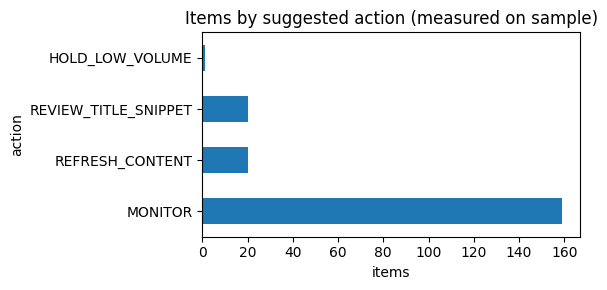

In [9]:
ax = df["action"].value_counts().plot.barh(figsize=(6, 3))
ax.set_title("Items by suggested action (measured on sample)"); ax.set_xlabel("items")
plt.tight_layout(); plt.savefig("work/figures/action_mix.png", dpi=150); plt.show()

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.